# Random Forest desde cero: demostración y experimentos

Este notebook reutiliza los módulos del proyecto y solo procesa telemetría de desarrollo. `Untitled.ipynb` es la referencia histórica, no es necesario ejecutarlo.

La validación interna usa los mismos incidentes en todas las corridas si no se cambia su tamaño ni la semilla de partición. El detector usa calibración previa de desarrollo: esta evaluación es exploratoria, no una estimación independiente. La reserva final no interviene.

In [4]:
import sys
from pathlib import Path

from IPython.display import display

# Resolver imports tanto desde la raíz como desde notebooks/.
project_root = Path.cwd().resolve()
if project_root.name == "notebooks":
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.forest_experiment import demo_roundtrip, load_development, run_experiment

# Usar None si los datos están en la ruta de config/topology.json.
DATA_ROOT = None
VALIDATION_INCIDENTS = 12
SPLIT_SEED = 42
FOREST_SEED = 42
# Cada pareja indica (incidentes completos de entrenamiento, árboles).
RUNS = [(12, 10), (24, 10)]
PLOT = True

In [3]:
# Ejecutar detección y asociación una sola vez; no es parte del tiempo de ajuste.
development = load_development(project_root, data_root=DATA_ROOT)
print(f"Preparación de desarrollo: {development.elapsed_sec:.3f} s")

Asociación de desarrollo: 12/72
Asociación de desarrollo: 24/72
Asociación de desarrollo: 36/72
Asociación de desarrollo: 48/72
Asociación de desarrollo: 60/72
Asociación de desarrollo: 72/72
Preparación de desarrollo: 20.413 s


## Tiempo de ejecución

El ajuste incluye el bootstrap y la construcción concurrente; no incluye detección, asociación ni selección de columnas. El tiempo de evaluación incluye predicción y ranking. Son mediciones de una corrida local, no un benchmark controlado. Los tamaños solicitados incluyen incidentes omitidos por el detector; se informa cuántos aportaron filas.

In [5]:
for train_size, tree_count in RUNS:
    result = run_experiment(
        development, train_incidents=train_size, validation_incidents=VALIDATION_INCIDENTS,
        split_seed=SPLIT_SEED, n_trees=tree_count, forest_seed=FOREST_SEED,
    )
    associated = result.train_audit.status.eq("associated").sum()
    print(f"Train: {associated}/{train_size} incidentes asociados, {len(result.X_train)} filas, "
          f"{result.X_train.shape[1]} variables, {tree_count} árboles")
    print(f"Ajuste: {result.fit_seconds:.3f} s; evaluación: {result.evaluation_seconds:.3f} s")

Train: 12/12 incidentes asociados, 181 filas, 44 variables, 10 árboles
Ajuste: 0.028 s; evaluación: 0.036 s
Train: 24/24 incidentes asociados, 361 filas, 44 variables, 10 árboles
Ajuste: 0.037 s; evaluación: 0.037 s


## Calidad exploratoria de la última corrida

Se seleccionan columnas finitas y variables solo en entrenamiento; no hay imputación. Si a un candidato le falta una variable seleccionada, se omite el incidente completo del ranking, pero se cuenta en la cobertura. Top-1, Top-3 y MRR se calculan solo sobre incidentes puntuados. Los empates se resuelven por nombre de servicio.

,Valor
attempted,12.000000
associated,12.000000
scored,12.000000
tied_first,1.000000
false_alerts_before_injection,0.000000
top_1,0.833333
top_3,1.000000
mrr,0.902778
precision,0.833333
recall,0.833333


,incident_id,association_status,false_alerts_before_injection,scoring_status,candidates,predicted_service,root_rank,top_tie_size
0,re2ss_catalogue_delay_1,associated,0,scored,15,catalogue,1,1
1,re2ss_catalogue_mem_2,associated,0,scored,15,catalogue,1,1
2,re2ss_catalogue_socket_3,associated,0,scored,15,catalogue,1,1
3,re2ss_orders_cpu_1,associated,0,scored,15,orders,1,1
4,re2ss_orders_delay_2,associated,0,scored,15,orders,1,1
5,re2ss_orders_loss_2,associated,0,scored,15,orders,1,1
6,re2ss_orders_mem_2,associated,0,scored,15,orders,1,1
7,re2ss_payment_disk_2,associated,0,scored,15,payment,1,1
8,re2ss_payment_loss_1,associated,0,scored,15,front-end,3,2
9,re2ss_user_cpu_2,associated,0,scored,15,user,1,1


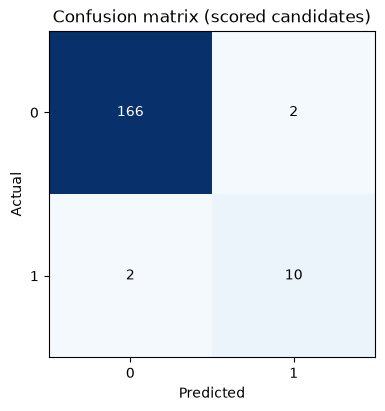

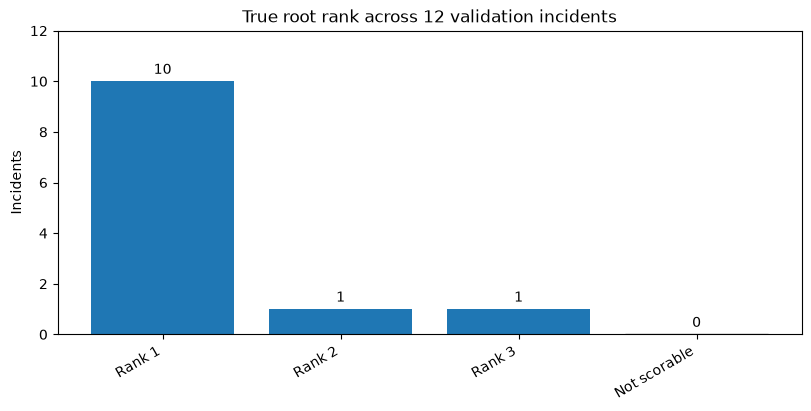

In [6]:
display(result.validation.summary.to_frame("Valor"), result.validation.incidents)
if PLOT:
    import matplotlib.pyplot as plt
    from src.forest_plots import plot_validation

    plot_validation(result.validation)
    plt.show()

In [7]:
# Mostrar las variables asignadas a cada árbol y tres predicciones tras recargar el JSON.
# Son filas de entrenamiento para demostrar la interfaz, no métricas de calidad.
print(result.forest.training_features)
display(demo_roundtrip(result.forest, result.X_train.head(3)))

(('latency-90__window_count', 'socket__window_missing_fraction', 'latency-90__present', 'cpu__window_missing_fraction', 'socket__baseline_std', 'diskio__baseline_missing_fraction'), ('mem__baseline_mean', 'mem__window_missing_fraction', 'diskio__baseline_missing_fraction', 'workload__window_missing_fraction', 'error__window_missing_fraction', 'socket__window_count'), ('workload__window_count', 'workload__present', 'cpu__baseline_count', 'mem__baseline_mean', 'diskio__window_count', 'diskio__window_missing_fraction'), ('diskio__window_missing_fraction', 'cpu__present', 'error__window_count', 'diskio__baseline_count', 'latency-50__window_count', 'latency-50__present'), ('diskio__baseline_count', 'latency-50__window_missing_fraction', 'observed_metric_count', 'error__present', 'cpu__baseline_missing_fraction', 'cpu__window_missing_fraction'), ('latency-50__window_count', 'diskio__baseline_count', 'mem__window_count', 'latency-50__baseline_count', 'cpu__baseline_count', 'workload__baseline

tree_1  tree_2  tree_3  tree_4    tree_5  \
incident_id       service                                                 
re2ss_carts_cpu_2 carts      1.000000     1.0     0.0     1.0  0.666667   
                  carts-db   0.000000     0.0     0.0     0.0  0.000000   
                  catalogue  0.026316     0.0     0.0     0.0  0.000000   

                               tree_6  tree_7  tree_8    tree_9  tree_10  \
incident_id       service                                                  
re2ss_carts_cpu_2 carts      0.937500     1.0     1.0  1.000000      1.0   
                  carts-db   0.000000     0.0     0.0  0.000000      0.0   
                  catalogue  0.014706     0.0     0.0  0.186441      0.0   

                             forest_score  
incident_id       service                  
re2ss_carts_cpu_2 carts          0.860417  
                  carts-db       0.000000  
                  catalogue      0.022746

## Entrenamiento final y exportación

Activa `EXPORT_FINAL_FOREST` para entrenar con todos los incidentes asociables de desarrollo y guardar el paquete local. El destino debe ser nuevo. Esta celda prepara el modelo para la evaluación posterior de la reserva.

In [ ]:
from src.final_training import train_final_forest

EXPORT_FINAL_FOREST = False
FINAL_OUTPUT = project_root / "artifacts" / "final_forest"

if EXPORT_FINAL_FOREST:
    manifest = train_final_forest(project_root, FINAL_OUTPUT, data_root=DATA_ROOT)
    print(f"Bosque guardado en {FINAL_OUTPUT}")
    print(f"Incidentes asociados: {manifest['associated_incidents']}/{manifest['development_incidents']}")
    print(f"Filas: {manifest['training_rows']}; variables: {len(manifest['features'])}")

## Evaluación final de la reserva

La evaluación usa el paquete final ya exportado. Mantén `EVALUATE_FINAL_HOLDOUT = False` para consultar un informe existente o durante el trabajo de desarrollo.

In [ ]:
import json
from src.final_evaluation import evaluate_final_forest

EVALUATE_FINAL_HOLDOUT = False
FINAL_REPORT = project_root / "reports" / "final_evaluation"

if EVALUATE_FINAL_HOLDOUT:
    evaluate_final_forest(FINAL_OUTPUT, FINAL_REPORT, data_root=DATA_ROOT)
if (FINAL_REPORT / "summary.json").is_file():
    display(json.loads((FINAL_REPORT / "summary.json").read_text(encoding="utf-8")))